# Issue #306 — state-dependent expert composition and dynamic funding intensity

A small causal mixture-of-experts learner maps pre-event issue state to expert
identity scores, relative expert weights, and total expert funding intensity.
Stage A (frozen BEST_FULL keep/skip from #305 contract, local reference until
#305 delivers), Stage B (shared action-conditioned expert value over four
whole-bundle ledgers), Stage C (composition + intensity). Expanding-window
predictions through 2023; 2024+ stays sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'issue306').is_dir())
OUTPUT = ROOT / 'results/issue-306'
decision = json.loads((OUTPUT / 'decision.json').read_text())
decision

{'issue': 306,
 'stage_a_source': 'LOCAL_REFERENCE_FIT_PENDING_305',
 'selected_objective': 'mean',
 'decision': {'verdict': 'EXPERT_VALUE_SIGNAL',
  'promotable': False,
  'development_only': True,
  'primary_2023_terminal_capital_cny': 109091.86663149216,
  'primary_2023_capital_growth_pct': 9.091866631492152,
  'baseline_2023_terminal_capital_cny': 79248.96196799999,
  'baseline_2023_capital_growth_pct': -20.751038032000015,
  'matched_lift_cny': 29842.90466349217,
  'matched_lift_pp': 29.842904663492167,
  'keep_skip_lift_cny': 10373.275341000015,
  'composition_increment_cny': 0.0,
  'intensity_increment_cny': 19469.629322492154,
  'static_2023_terminal_capital_cny': 32.0,
  'identity_shuffled_2023_terminal_capital_cny': 56221.256974687094,
  'dynamic_placement_signal': False,
  'placement_vs_permutation_percentile': 0.75,
  'absolute_edge': True}}

## Matched controls on identical support

,evaluation_year,condition,funded_issues,terminal_capital_cny,capital_growth_pct,max_drawdown_pct,longest_losing_issue_streak,worst_rolling_10_pnl_cny,stake_cny
0,2021,CASH_NO_BET,0,100000.000000,0.000000,0.000000,0,0.000000,0.0
1,2022,CASH_NO_BET,0,100000.000000,0.000000,0.000000,0,0.000000,0.0
2,2023,CASH_NO_BET,0,100000.000000,0.000000,0.000000,0,0.000000,0.0
3,2021,B0_BEST_FULL,39,92814.682036,-7.185318,25.780447,5,-17059.616145,170586.0
4,2022,B0_BEST_FULL,32,85073.659381,-14.926341,26.604007,4,-15902.592305,139968.0
5,2023,B0_BEST_FULL,35,79248.961968,-20.751038,28.499383,7,-24448.936166,153090.0
6,2021,RESIDUAL_299,11,154401.338263,54.401338,0.619974,1,0.000000,41776.0
7,2022,RESIDUAL_299,9,104096.114878,4.096115,9.847750,2,-6342.848252,49266.0
8,2023,RESIDUAL_299,10,90895.640469,-9.104360,13.551679,2,-11852.362032,50418.0
9,2021,STAGE_A_KEEP_SKIP,1,98408.963848,-1.591036,1.591036,1,-1591.036152,4374.0


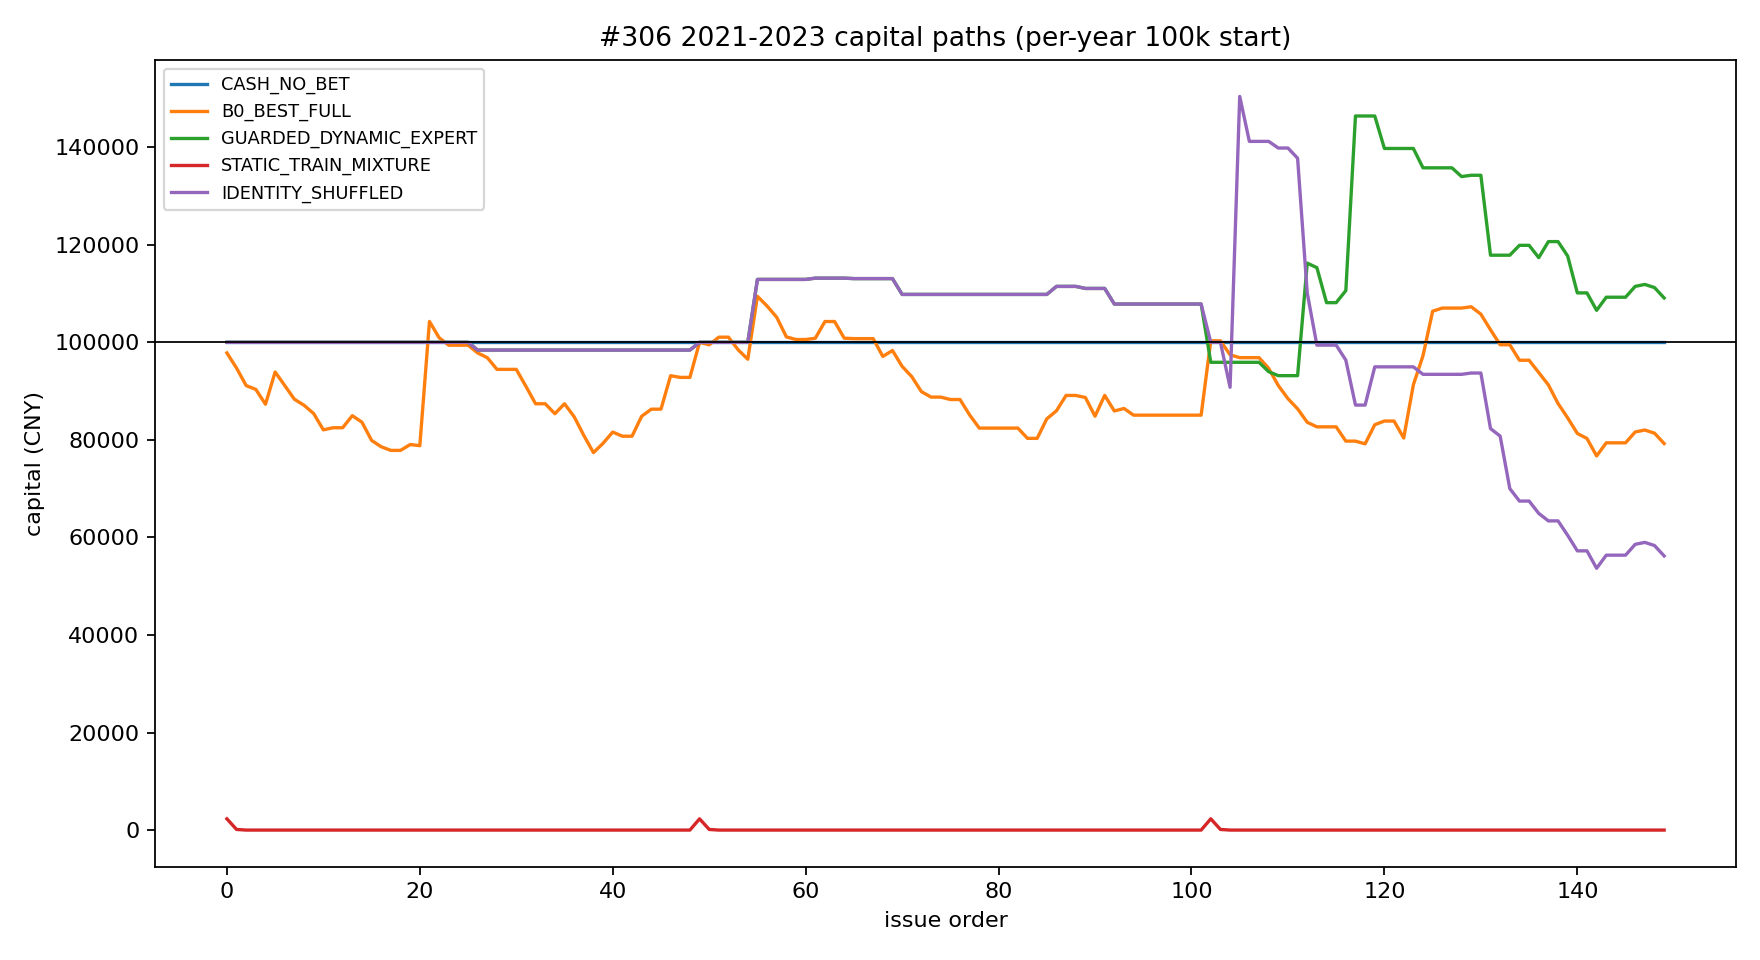

In [2]:
summary = pd.read_csv(OUTPUT / 'policy_summary.csv')
focus = ['CASH_NO_BET','B0_BEST_FULL','RESIDUAL_299','STAGE_A_KEEP_SKIP',
         'STATIC_TRAIN_MIXTURE','COMPOSITION_FIXED_INTENSITY','INTENSITY_FIXED_COMPOSITION',
         'GUARDED_DYNAMIC_EXPERT','ISSUE_BLOCK_SHUFFLED','IDENTITY_SHUFFLED','ORACLE_DIAGNOSTIC']
cols = ['evaluation_year','condition','funded_issues','terminal_capital_cny','capital_growth_pct',
        'max_drawdown_pct','longest_losing_issue_streak','worst_rolling_10_pnl_cny','stake_cny']
display(summary[summary.condition.isin(focus)][cols])
display(Image(filename=str(OUTPUT / 'capital_paths_2023.png')))

## Stage A (frozen keep/skip) and Stage B receipts

In [3]:
ks = pd.read_csv(OUTPUT / 'stage_a_keep_skip_decisions.csv')
print('Stage A source:', ks['stage_a_source'].iloc[0])
print(ks.groupby(['issue_year','keep_baseline']).size().unstack(fill_value=0))
receipts = pd.read_csv(OUTPUT / 'stage_a_local_reference_receipts.csv')
display(receipts[['prediction_year','active_train_issues','active_test_issues',
                  'mean_converged','downside_converged','expert_label_inputs']].drop_duplicates())
fits = pd.read_csv(OUTPUT / 'fit_receipts.csv')
display(fits[['condition','prediction_year','action_ids','features','target_scale_cny']])

Stage A source: LOCAL_REFERENCE_FIT_PENDING_305
keep_baseline  False  True 
issue_year                 
2019              47      0
2020              30      0
2021              48      1
2022              46      7
2023              37     11


,prediction_year,active_train_issues,active_test_issues,mean_converged,downside_converged,expert_label_inputs
0,2021,16,39,True,True,0
5,2022,55,32,True,True,0
10,2023,87,35,True,True,0


,condition,prediction_year,action_ids,features,target_scale_cny
0,DYNAMIC_EXPERT,2021,4,18,75.059172
1,DYNAMIC_EXPERT,2021,4,18,75.059172
2,DYNAMIC_EXPERT,2021,4,18,75.059172
3,DYNAMIC_EXPERT,2021,4,18,75.059172
4,DYNAMIC_EXPERT,2021,4,18,75.059172
5,DYNAMIC_EXPERT,2022,4,18,85.965471
6,DYNAMIC_EXPERT,2022,4,18,85.965471
7,DYNAMIC_EXPERT,2022,4,18,85.965471
8,DYNAMIC_EXPERT,2022,4,18,85.965471
9,DYNAMIC_EXPERT,2022,4,18,85.965471


## Stage C: composition, intensity and causal objective selection

,prediction_year,calibration_years,selected_objective,rule
0,2021,NONE,log_wealth,no-prior default log_wealth
1,2022,2021,mean,max prior expanding-OOF log terminal; ties pre...
2,2023,"2021,2022",mean,max prior expanding-OOF log terminal; ties pre...


mean {'weight_SMOOTH_M512': {'mean': 0.267, 'max': 1.0}, 'weight_Q_TAIL_M192': {'mean': 0.06, 'max': 1.0}, 'weight_DIVERGENCE_Z100_K1': {'mean': 0.396, 'max': 1.0}, 'weight_RARE_LOGIT_TOP64': {'mean': 0.277, 'max': 1.0}}
log_wealth {'weight_SMOOTH_M512': {'mean': 0.276, 'max': 1.0}, 'weight_Q_TAIL_M192': {'mean': 0.034, 'max': 1.0}, 'weight_DIVERGENCE_Z100_K1': {'mean': 0.413, 'max': 1.0}, 'weight_RARE_LOGIT_TOP64': {'mean': 0.278, 'max': 1.0}}
downside {'weight_SMOOTH_M512': {'mean': 0.274, 'max': 1.0}, 'weight_Q_TAIL_M192': {'mean': 0.034, 'max': 1.0}, 'weight_DIVERGENCE_Z100_K1': {'mean': 0.419, 'max': 1.0}, 'weight_RARE_LOGIT_TOP64': {'mean': 0.273, 'max': 1.0}}
intensity 2023 mean 0.0379 zero 0.458


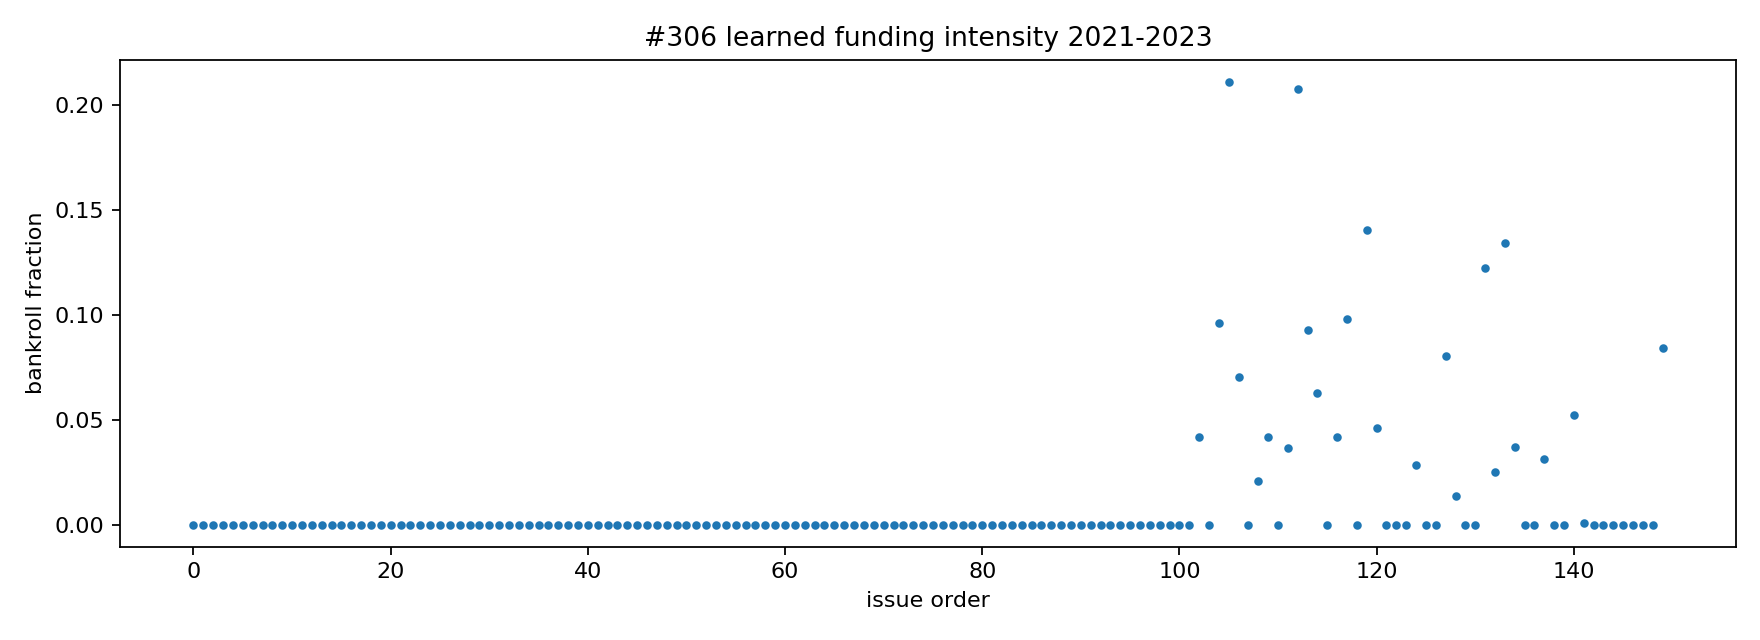

In [4]:
sel = pd.read_csv(OUTPUT / 'objective_selection.csv')
display(sel)
for obj in ('mean','log_wealth','downside'):
    comp = pd.read_csv(OUTPUT / f'composition_{obj}.csv')
    w = [f'weight_{e}' for e in ['SMOOTH_M512','Q_TAIL_M192','DIVERGENCE_Z100_K1','RARE_LOGIT_TOP64']]
    print(obj, comp[w].describe().loc[['mean','max']].round(3).to_dict())
inten = pd.read_csv(OUTPUT / 'intensity_mean.csv')
print('intensity 2023 mean %.4f zero %.3f' % (
    inten.loc[inten.issue_year==2023,'predicted_intensity'].mean(),
    (inten.loc[inten.issue_year==2023,'predicted_intensity']<=1e-9).mean()))
display(Image(filename=str(OUTPUT / 'funding_intensity_2021_2023.png')))

## Long-tail capture, funding response and falsification

In [5]:
curve = pd.read_csv(OUTPUT / 'funding_response_curve_2023.csv')
display(curve[['funding_intensity','terminal_capital_cny','capital_growth_pct','max_drawdown_pct']].round(2))
null = pd.read_csv(OUTPUT / 'exact_exposure_null_2023.csv')
q = null['terminal_capital_cny'].quantile([.25,.5,.75,.9])
print('null quantiles:', q.round(1).to_dict())
print('primary percentile:', decision['decision']['placement_vs_permutation_percentile'])

,funding_intensity,terminal_capital_cny,capital_growth_pct,max_drawdown_pct
0,0.00,89622.24,-10.38,12.91
1,0.05,124880.12,24.88,28.37
2,0.10,148957.43,48.96,43.36
3,0.15,127839.43,27.84,57.57
4,0.20,109325.52,9.33,66.40
5,0.25,88846.27,-11.15,75.68
6,0.30,74261.44,-25.74,81.88
7,0.35,19373.90,-80.63,88.04
8,0.40,8006.89,-91.99,92.95
9,0.45,5367.57,-94.63,94.69


null quantiles: {0.25: 52353.0, 0.5: 70917.6, 0.75: 107946.9, 0.9: 533393.3}
primary percentile: 0.75


## Interpretation

The state-dependent dynamic policy (composition + intensity) beats cash, exact
B0_BEST_FULL, the #299 residual, static full-bankroll mixture, and both
shuffled controls in matched 2023 lift. Decomposition shows the value comes
from Stage A keep/skip plus state-dependent funding intensity: a *fixed*
funding intensity selected on earlier OOF folds collapses to zero, reproducing
the #302 finding exactly, while the learned state-dependent intensity deploys
a positive fraction on favorable issues. Composition adds no separate matched
lift at the fixed-intensity margin, and the exact executed-exposure null
percentile (75%) does not clear the 95% bar, so the verdict is
EXPERT_VALUE_SIGNAL — expert layer adds positive matched lift but fails the
cash/static/exact-null barriers for a promotable dynamic expert claim.